# 1. Регресиия
Регрессия - это зависимость среднего значения какой-либо велечины от некоторой другой величины или от нескольких других величин. В отличии от чисто функциональной зависимости $$y = f(x)$$, когда каждому значению независимой переменной ***x*** соотвествует одно определённое значение зависимой переменной одно определённое значение зависимой переменной *y*, при регресионной сязи одному и тому же значению независимой переменной(фактору) ***x*** могут соотвествовать в зависимости от конкретного случая различные занчения зависимосй переменной (отклика) ***y***.
Изучение регресии основано на том, что случайные величины ***X*** и ***Y*** связаны между собой вероятностной зависимостью: при каждом конкретном значении ***X = x*** величина ***Y*** является случайной величиной со вполне определённым распределием вероятностей. Зависимость зависимой переменной - отклика от одной независимой переменной - фактора или нескольких факторов называется урпавнением регресии. По количеству факторов выделяют парную выделяют парную (однофакторную) и множественную (многофакторную) регрессию. Для парной будет рассматривать следующие методы регресии: линейную, показательную, экспоненциальную, гиперболическую и параболическую. 

Регрессионный анализ - это раздел математической статистики, изучающих регрессионную зависимость между случайными величинами по статистическим данным. Цель регрисионного анализа состоит в опредлении общего вида уравнения регрессии, вычислении оценок неизвестных параметров, входящих в уравнение регрессии проверке статистических гипотез о регрессионной связи.

Таким образом, регрисионный анализ - набор статистических методов ислледования влияния одной или несколких независимых переменных ***X1,...,Xn*** на зависимую переменную ***Y***. Независимые переменные иначе называют регрессорами или предикторами, а зависимые переменные - критериальными переменными. 



## 1.1 Теоретический материал - Линейные регрессионные модели
Линейная регрессия (Linear regression) - модель зависимости перменной x от одной или нескольких других переменных (факторов, регрессоров, независимых переменных) с линейной функцией зависимости. Линейная регрессия относится к задаче определения "линиии наилучшего соотвествия" через набор точек данных и стала простым предшественником нелинейных методов, которые используются для обучения нейронных сетей. 

Цель линейной регресии - поиск линии, которая наилучшим образом соотвествует точкам. Напомним, что общее уравнение для прямой есть $f(x) = b + m * x$, где ***m*** - наклон линиии, а ***b*** - его сдвиг.

**Функция потерь - метод наименьших квадратов**
Функция потерь - это мера количества ошибок, которые наша линейная регрессия делает на наборе данных. Хотя есть разные функции потерь, все они вычисляют расстояние между предсказанным значением ***y(x)*** и его фактическим значением.
Одна очень распространенная функция потерь называется средней квадратичной ошибкой **MSE**. Чтобы вычислить - **MSE**, мы просто берем все значения ошибок, считаем их квадраты длин и усредняем.
**Задача экраполяции**
Допустим у нас есть много экспериментальных точек. Необходимо через них провести кривую, которая как можно ближе к этим точкам. При этом необходимо минимизировать среднюю квардратичную ошибку (**MSE**).
Для решения данной задачи в Python есть множество библиотек. Самым распространенным выступают:
```python
numpy - numpy.linalg.lstsq
scipy - scipy.linalg # Содержит все функции из numpy.linalg плюс часть новых функций, которых нет в numpy.linalg
```

### 1.1.1 Пример
***Задача:*** Проведем прямую $$ y = mx+b $$ через экспериментальные точки. 

0.9999999999999999 -0.9499999999999997


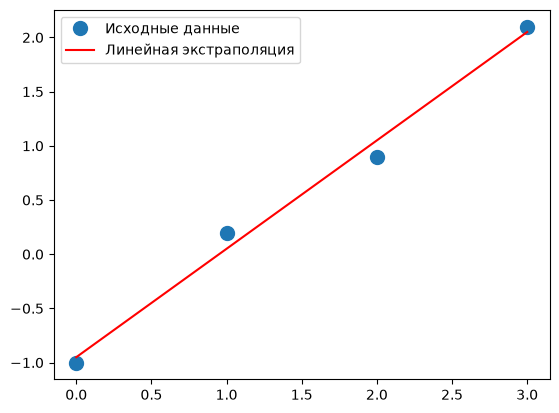

In [1]:
import numpy as np
x = np.array([0,1,2,3])
y = np.array([-1,0.2,0.9,2.1])

# Перепишем лиейное уравнение y = mx + c как y = Ap, где [[ x 1 ]] и p = [[m], [c]]
# Построим A по x:

A = np.vstack([x, np.ones(len(x))]).T
m,c = np.linalg.lstsq(A, y, rcond = None)[0]
print(m,c)

import matplotlib.pyplot as plt
plt.plot(x,y,'o',label='Исходные данные', markersize=10)
plt.plot(x,m*x+c,'r',label='Линейная экстраполяция')
plt.legend()
plt.show()

### 1.1.2 Пример
***Задача:*** Путь *x,y* - вектрона длиной *n>3* (точек > 3). Задача заключается в построении экстраполяционного полинома второго порядка (параболы)ю Таким образом, необходимо найти такие коэффиценты полином *a,b,c* по методу наименьших квадратов. Данные могут быть получены в результате измерений. Покажем пример генерации данных случайным образом и загрузки их из файла.

[-4.61382568 -4.05154593 -2.77194523 -1.69096066 -1.3011469  -0.40537247
  1.2198873   1.72353602  3.47280857  3.64704223  4.67371783]
[24.54336796 15.89043211  8.68787552  4.10974188  0.86872536 -0.24030946
  0.93317558  4.24287237  8.71567946 15.54356953 24.85645378]


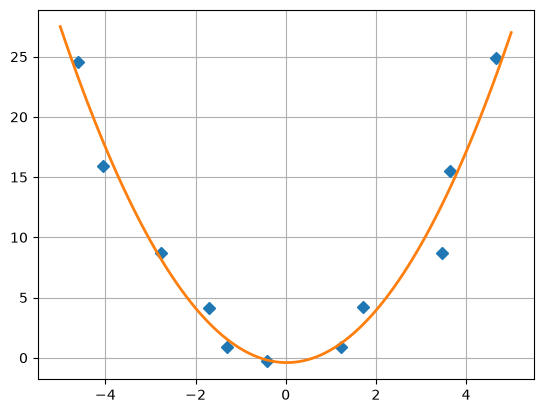

In [2]:
from numpy import *
from numpy.random import *
#генерируем случайные x и y
delta = 1.0
x = linspace(-5, 5, 11)
y = x**2+delta*(rand(11)-0.5)
x += delta*(rand(11)-0.5)

# записываем данные в файл
x.tofile('x_data.txt', '\n')
y.tofile('y_data.txt', '\n')

# читаем данные из файлов
x = fromfile('x_data.txt', float, sep='\n')
y = fromfile('y_data.txt', float, sep='\n')

print(x)
print(y)

# Нахождение коэффицентов функции вида y = ax^2 + bx +c методом наименьших квадратов
# задаем вектор m = [x**2, x, E]
m = vstack((x**2, x, ones(11))).T
# находим коэффиценты при составляющих вектор m
s = np.linalg.lstsq(m, y, rcond = None)[0]

# на отрезке [-5,5]
x_prec = linspace(-5,5,101)
# рисуем точки
plt.plot(x, y, 'D')
# рисуем кривую вида y = ax^2 + bx +c, подставляя из решения коэффиценты s[0], s[1], s[2]
plt.plot(x_prec, s[0] * x_prec**2 + s[1] * x_prec+s[2],'-',lw=2)
plt.grid()
plt.savefig('парабола.png')

### 1.1.3 Пример
***Задача:*** по данным предыдущего примера постройте экстраполяцию полинома третьего порядка

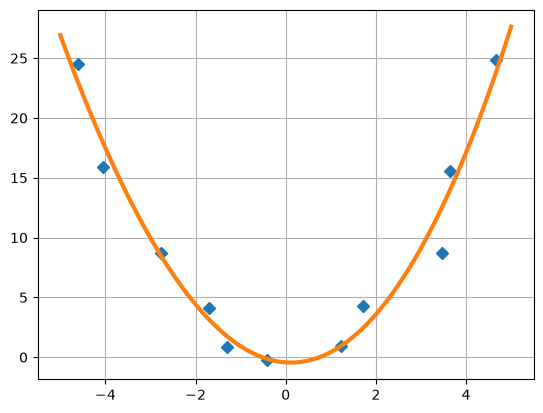

In [3]:
# Нахождение коэффицентов функции вида y = ax^3 + bx^2 + cx + d методом наименьших квадратов
# задаем вектор m = [x**3, x, E]
m = vstack((x**3, x**2, x, ones(11))).T
# находим коэффиценты при составляющих вектора m
s = np.linalg.lstsq(m, y, rcond = None)[0]

# на отрезке [-5,5]
x_prec = linspace(-5, 5, 101)
# рисуем точки
plt.plot(x, y, 'D')
# рисуем кривую вида y = ax^3 + bx^2 + cx +d, поставляя из решения коэфиценты s[0], s[1], s[2], s[3]
plt.plot(x_prec, s[0] * x_prec**3 + s[1] * x_prec**2 + s[2]*x_prec + s[3],'-',lw=3 )
plt.grid()
plt.savefig('полином 3-й степени.png')  


***Задание:*** представьте собственне данные и постройте экстраполяцию полиномами первой, второй и третьей степени.

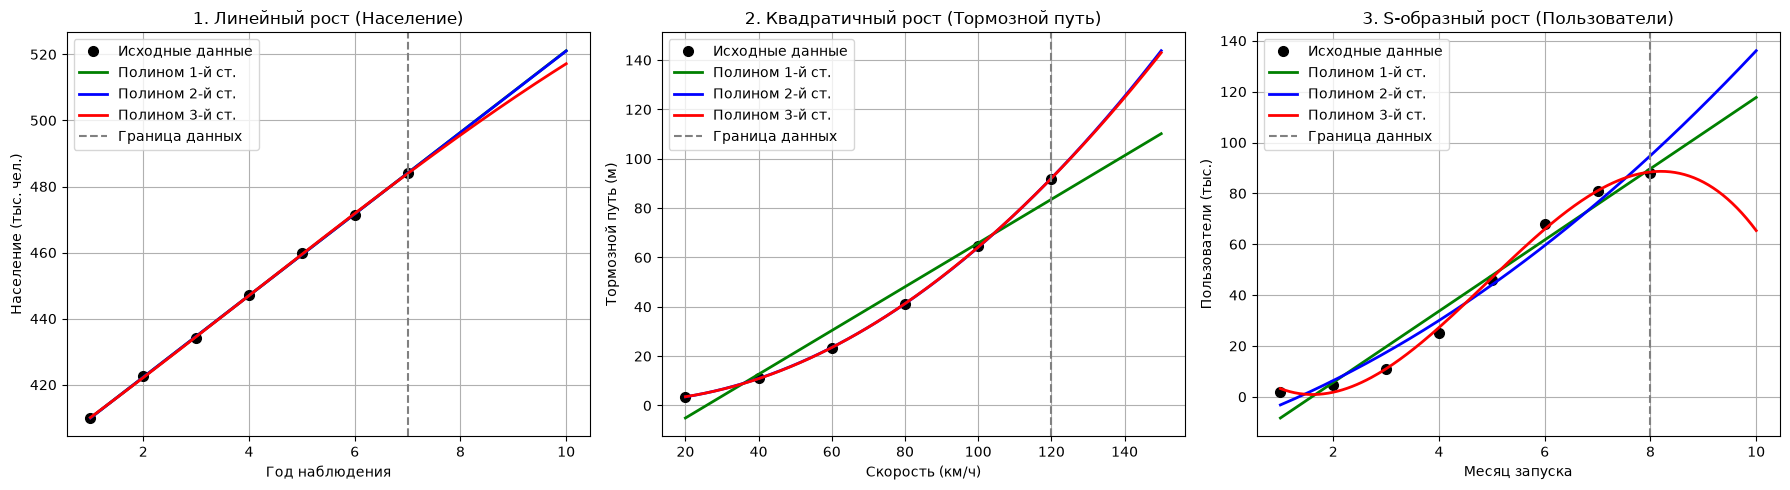

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Задаем примеры данных
datasets = [
    #  Зависимости населения города от года проведенной переписи (лийеный рост)
    {
        'title': '1. Линейный рост (Население)',
        'x': np.array([1, 2, 3, 4, 5, 6, 7], dtype=float),
        'y': np.array(
            [410.0, 422.5, 434.0, 447.2, 459.8, 471.5, 484.0], dtype=float
        ),
        'extrap_steps': 3,
        'xlabel': 'Год наблюдения',
        'ylabel': 'Население (тыс. чел.)',
    },
    # Зависимость тормозного пути от скорости движения автомобиля
    {
        'title': '2. Квадратичный рост (Тормозной путь)',
        'x': np.array([20, 40, 60, 80, 100, 120], dtype=float),
        'y': np.array([3.5, 11.0, 23.5, 41.0, 64.5, 92.0], dtype=float),
        'extrap_steps': 30,
        'xlabel': 'Скорость (км/ч)',
        'ylabel': 'Тормозной путь (м)',
    },
    # Рост пользователей относительно давности запуска интернет-портала
    {
        'title': '3. S-образный рост (Пользователи)',
        'x': np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float),
        'y': np.array(
            [2.0, 4.5, 11.0, 25.0, 46.0, 68.0, 81.0, 88.0], dtype=float
        ),
        'extrap_steps': 2,
        'xlabel': 'Месяц запуска',
        'ylabel': 'Пользователи (тыс.)',
    },
]

# Строим 3 графика
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['green', 'blue', 'red']

# Проходим по каждому набору данных
for ax, data in zip(axes, datasets):
  x = data['x']
  y = data['y']
  x_extrap = np.linspace(min(x), max(x) + data['extrap_steps'], 200)

  
  ax.plot(x, y, 'ko', markersize=7, label='Исходные данные')

  # Внутренний цикл строит полиномы 1, 2 и 3 степени
  for degree, color in zip([1, 2, 3], colors):
    # Ищем коэфиценты уравнения
    coeffs = np.polyfit(x, y, degree)
    # Строим полином порядка на основании коэфицентов (coeffs)
    y_extrap = np.polyval(coeffs, x_extrap)
    ax.plot(
        x_extrap,
        y_extrap,
        color=color,
        lw=2,
        label=f'Полином {degree}-й ст.',
    )

  ax.axvline(max(x), color='gray', linestyle='--', label='Граница данных')
  ax.set_title(data['title'])
  ax.set_xlabel(data['xlabel'])
  ax.set_ylabel(data['ylabel'])
  ax.grid(True)
  ax.legend()

plt.tight_layout()
plt.savefig('сравнение_всех_примеров.png')
plt.show()


### 1.1.4 Пример
Задача: необхоидмо проверить гипотезу, что наши точечно заданная функция ложится на кривую вида $ f(x,b) = b_0 + b_1exp(-b2x^2) $

0.00021561114482270222
0.1128413490398901


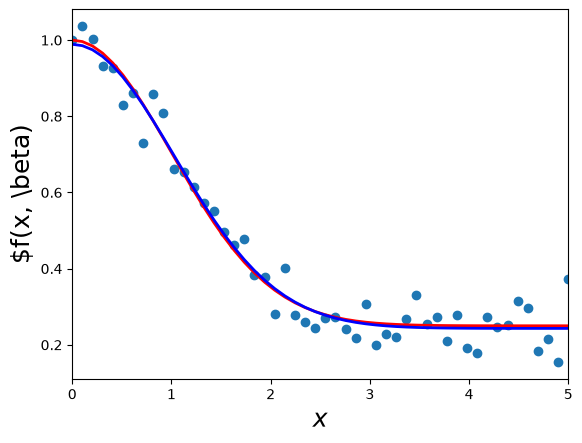

[0.         0.10204082 0.20408163 0.30612245 0.40816327 0.51020408
 0.6122449  0.71428571 0.81632653 0.91836735 1.02040816 1.12244898
 1.2244898  1.32653061 1.42857143 1.53061224 1.63265306 1.73469388
 1.83673469 1.93877551 2.04081633 2.14285714 2.24489796 2.34693878
 2.44897959 2.55102041 2.65306122 2.75510204 2.85714286 2.95918367
 3.06122449 3.16326531 3.26530612 3.36734694 3.46938776 3.57142857
 3.67346939 3.7755102  3.87755102 3.97959184 4.08163265 4.18367347
 4.28571429 4.3877551  4.48979592 4.59183673 4.69387755 4.79591837
 4.89795918 5.        ]
[0.99931015 1.03692537 1.00182476 0.93117504 0.92702079 0.82909209
 0.8606259  0.73087095 0.85792416 0.80968451 0.66222259 0.6547743
 0.61510747 0.57137412 0.55167142 0.49585933 0.46084192 0.47705311
 0.38345051 0.37904545 0.28211791 0.40083048 0.27751947 0.25989918
 0.24445656 0.27039062 0.27411771 0.24208669 0.21886209 0.30753514
 0.19853251 0.22851496 0.22015186 0.26906127 0.33006018 0.25539425
 0.27392662 0.2094958  0.27793069 0.192

In [5]:
#Добавим шума в данные, сделанные по функции f(x,b) с коэффицентоами b = (0.25, 0.75, 0.5)
beta = (0.25, 0.75, 0.5)
def f(x, b0, b1, b2):
    return b0 + b1 * np.exp(-b2 * x **2)
xdata = np.linspace(0, 5, 50)
y = f(xdata, *beta)
# зашушмляем эти данные
ydata = y + 0.05 * np.random.randn(len(xdata))
# Используем функцию для получение в виде коэффицентов функции f(x) для указанным xdata и ydata
import scipy as sp
from scipy.optimize import curve_fit

beta_opt, beta_cov = sp.optimize.curve_fit(f, xdata, ydata)
beta_opt
# Вычислим линейное отклонение
lin_dev = sum(beta_cov[0])
print(lin_dev)

# Вычисляем квадратичное отклонение
residuals = ydata - f(xdata, *beta_opt)
fres = sum(residuals**2)
print(fres)

fig, ax = plt.subplots()
ax.scatter(xdata, ydata)
ax.plot(xdata, y, 'r', lw=2)
ax.plot(xdata, f(xdata, *beta_opt), 'b', lw=2)
ax.set_xlim(0, 5)
ax.set_xlabel(r"$x$", fontsize=18)
ax.set_ylabel(r"$f(x, \beta)", fontsize=18)
plt.show()
print(xdata)
print(ydata)

### 1.1.5 Пример
***Задача:*** Необходимо проверить гипотезу, что наши точечно заданная функция ложится на кривые вида:
1) $ f(x,b) = b_0 + b_1x $
2) $ f(x,b) = b_0 + b_1x + b_2x^2 $
3) $ f(x,b) = b_0 + b_1ln(x) $
4) $f(x, b) = b_0 x^{b_1}$


[0.24670623 0.75426865]
0.00010227731551150829
289.033274420145


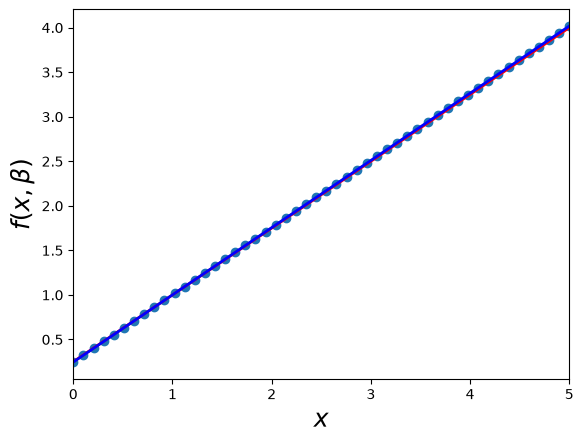

In [6]:
#решение
#1
#Добавим шума в данные, сделанные по функции f(x,b) с коэффицентами b = (0.25, 0.75)
beta = (0.25, 0.75)
def f(x, b0, b1):
    return b0 + b1 * x
# зададим массивы точке xi
xdata = np.linspace(0, 5, 50)
y = f(xdata, *beta)
# зашумляем эти данные
ydata = y + 0.05 * np.random.randn(len(xdata))
beta_opt,beta_cov = sp.optimize.curve_fit(f, xdata, ydata)
print(beta_opt)
# вычислим линейное отклонение
lin_dev = sum(beta_cov[0])
print(lin_dev)

# вычислим квадратичное отклонение
residuals = ydata = f(xdata,*beta_opt)
fres = sum(residuals**2)
print(fres)

fig, ax = plt.subplots()
ax.scatter(xdata, ydata)
ax.plot(xdata, y, 'r', lw=2)
ax.plot(xdata, f(xdata, *beta_opt), 'b', lw=2)
ax.set_xlim(0, 5)
ax.set_xlabel(r"$x$", fontsize=18)
ax.set_ylabel(r"$f(x, \beta)$", fontsize=18)
plt.show()

Линейная: b0 + b1*x:
  истинные:  (0.25, 0.75)
  найденные: (np.float64(0.2582), np.float64(0.7475))
  RSS = 0.1280

Квадратичная: b0 + b1*x + b2*x²:
  истинные:  (0.25, 0.75, 0.5)
  найденные: (np.float64(0.2004), np.float64(0.7852), np.float64(0.4939))
  RSS = 0.1097

Логоримфическая: b0 + b1_ln(x):
  истинные:  (1.0, 2.0)
  найденные: (np.float64(1.0063), np.float64(2.0008))
  RSS = 0.1169

Степенная: b0·x^b1:
  истинные:  (1.0, 2.0)
  найденные: (np.float64(1.0021), np.float64(1.9989))
  RSS = 0.1047



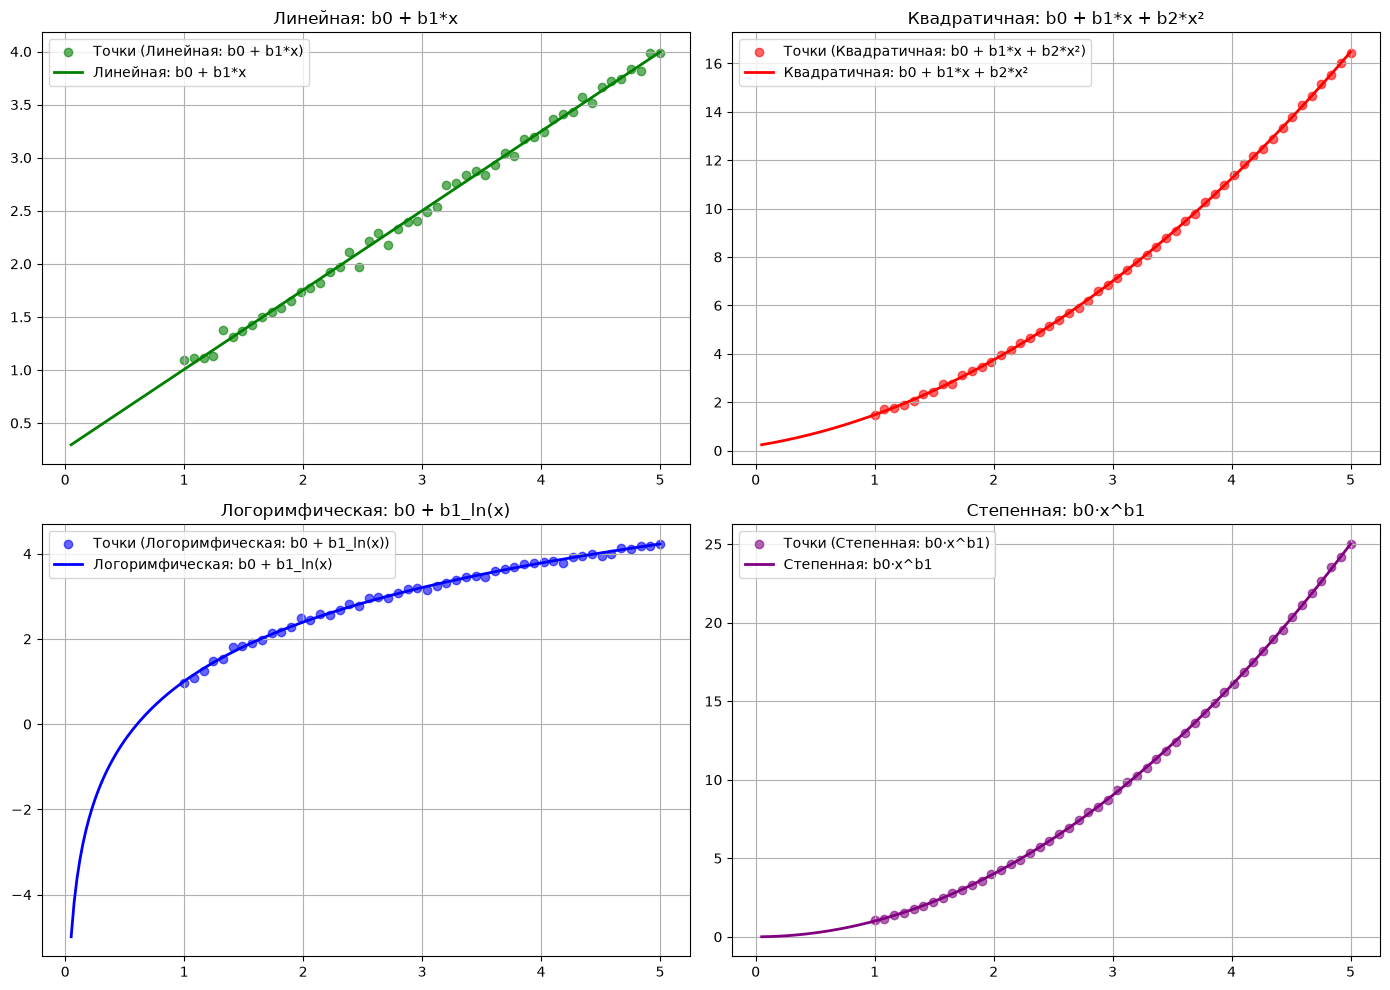

In [ ]:
### Решение через ООП 
# общая логика: обучение, расчет ошибки, составления графика
class BaseFitter:
    # Добавьте color='blue' сюда, в скобки:
    def __init__(self, name, color, beta_true):
        self.name = name
        self.color = color
        self.beta_true = beta_true
        self.beta_opt = None
        self.beta_cov = None

    @staticmethod
    def formula(x, *beta):
        raise NotImplementedError("Нужно определить формулу в дочернем классе")

    def generate_data(self, N=50, noise=0.05, x_range=(1, 5), seed=42):
       x = np.linspace(*x_range, N)
       y_clean = self.formula(x, *self.beta_true)
       y = y_clean + noise * np.random.randn(len(x))
       return x, y 

    def fit(self, xdata, ydata):
        self.beta_opt, self.beta_cov = curve_fit(self.formula, xdata, ydata)

    # Метод предсказания значений Y для любых новых X
    def predict(self, x):
        if self.beta_opt is None:
            raise ValueError('Сначала обучите модель методом fit()')
        return self.formula(x, *self.beta_opt)

    # Метод вычисления квадратичного отклонения (RSS)
    def get_squared_error(self, xdata, ydata):
        residuals = ydata - self.predict(xdata)
        return np.sum(residuals**2)

     # Метод отрисовки кривой
    def plot_data(self, ax, xdata, ydata):
        ax.scatter(
            xdata, ydata, color=self.color, alpha=0.6, label=f'Точки ({self.name})'
        )

    def plot_curve(self, ax, x_range):
        y_pred = self.predict(x_range)
        ax.plot(x_range, y_pred, color=self.color, lw=2, label=self.name)

# 1) Линейная:  f(x) = b0 + b1·x
class LinearModel(BaseFitter):
  def __init__(self):
    super().__init__(name='Линейная: b0 + b1*x', color="green", beta_true=(0.25, 0.75))

  @staticmethod
  def formula(x, b0, b1):
    return b0 + b1 * x

# 2) Квадратичная:  f(x) = b0 + b1·x + b2·x²
class QuadraticModel(BaseFitter):
  def __init__(self):
    super().__init__(name='Квадратичная: b0 + b1*x + b2*x²', color='red', beta_true=(0.25, 0.75, 0.5))

  @staticmethod
  def formula(x, b0, b1, b2):
    return b0 + b1 * x + b2 * x**2

# 3) Логарифмическая:  f(x) = b0 + b1·ln(x)
class LogorithmicModel(BaseFitter):
    def __init__(self):
        super().__init__(name='Логоримфическая: b0 + b1_ln(x)', color='blue', beta_true=(1.0, 2.0))

    @staticmethod
    def formula(x, b0, b1):
        return b0 + b1 * np.log(x)


# 4) Степенная:  f(x) = b0·x^b1
class PowerModel(BaseFitter):
    def __init__(self):
      super().__init__(name='Степенная: b0·x^b1', color='purple', beta_true=(1.0, 2.0))
    
    @staticmethod
    def formula(x, b0, b1):
       return b0 * x ** b1

if __name__ == '__main__':

    models = [LinearModel(), QuadraticModel(), LogorithmicModel(), PowerModel()]

    datasets = [m.generate_data(N=50, noise=0.05) for m in models]

    # Обучение + вывод
    for model, (xd, yd) in zip(models, datasets):
        model.fit(xd, yd)
        print(f'{model.name}:')
        print(f'  истинные:  {model.beta_true}')
        print(f'  найденные: {tuple(np.round(model.beta_opt, 4))}')
        print(f'  RSS = {model.get_squared_error(xd, yd):.4f}\n')

    # Графики 2×2
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    x_smooth = np.linspace(0.05, 5, 200)

    for ax, model, (xd, yd) in zip(axes.flatten(), models, datasets):
        model.plot_data(ax, xd, yd)
        model.plot_curve(ax, x_smooth)
        ax.set_title(model.name)
        ax.legend(); ax.grid(True)

    plt.tight_layout()
    plt.show()